# Space Science — from the Moon to the outer solar system

Once a vehicle escapes the atmosphere, navigation becomes orbital mechanics:
*where are the planets, and what is the cheapest path between them?*  This notebook
builds from the simplest analytic model (a two-impulse Hohmann transfer) up to a
full N-body EKF-tracked cruise with real-time trajectory correction.

| Section | Topic | Key API |
|---------|-------|---------|
| 1 | Trans-lunar coast — Earth ↔ Moon | `TransLunarModel`, `lunar_porkchop` |
| 2 | Earth → Mars: Hohmann → porkchop → N-body EKF | `hohmann_transfer`, `porkchop`, `InterplanetaryModel` |
| 2d | Mid-course TCM — trajectory correction | `InterplanetaryModel(control=True)` |
| 3 | Earth → Jupiter: same framework, longer cruise | `InterplanetaryModel`, `porkchop` |
| 4 | Gravity assist: Jupiter→Saturn slingshot | `gravity_assist`, `hohmann_sequence`, `flyby_porkchop` |
| 5 | Second TCM from EKF covariance at 80 % TOF | EKF covariance → re-Lambert |
| 6 | Cassini VVEJGA: Earth→V→V→E→J→Saturn replication | `chain_lambert`, `plot_multi_leg` |

**Transfer methods used throughout:**

| Method | What it solves | Accuracy | When used |
|--------|---------------|----------|-----------|
| **Hohmann** | Two-impulse transfer between *circular, coplanar* orbits — analytic | Approximate | Quick Δv/TOF estimates |
| **Lambert** | Any two positions + time of flight, solved numerically | Exact (two-body) | Porkchop scan, trajectory seeds |
| **N-body EKF** | Lambert initial conditions propagated under Sun + planet perturbations, filtered | Realistic | Cruise simulation & navigation |

Ephemeris via astropy `builtin` (network-free JPL kernels).

In [1]:
%pip install numpy matplotlib astropy > /dev/null
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
np.seterr(all="ignore")

from kalman.apps.space import (TransLunarModel, InterplanetaryModel,
                               hohmann_transfer, lambert, porkchop, best_departure,
                               plot_solar_system, plot_porkchop,
                               gravity_assist, hohmann_sequence, flyby_porkchop,
                               plot_flyby_porkchop, plot_gravity_assist, plot_two_leg,
                               chain_lambert, plot_multi_leg,
                               lunar_porkchop, plot_porkchop)
from kalman.runtime.astro import (planet_positions, body_state, launch_site_state,
                                  R_EARTH, KM, D_MOON, GM_EARTH, GM_SUN, LU, DAY, D_SUN)
AU = D_SUN                    # 1 astronomical unit in Mm

Note: you may need to restart the kernel to use updated packages.


## 0 — The solar system, right now

`planet_positions()` returns the exact heliocentric position of every planet (and the Moon) at a
given time from the JPL-style `builtin` ephemeris — no download required.


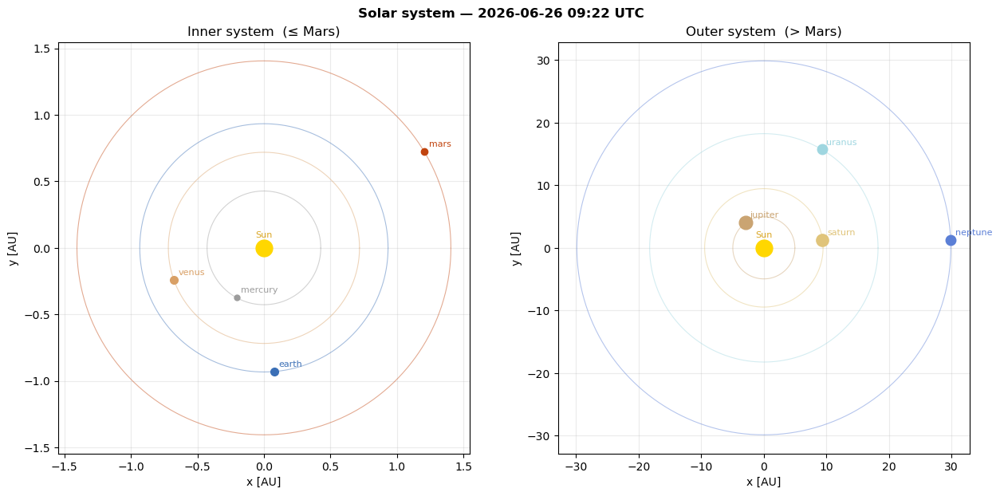

In [2]:
# Where is everything right now? Sun + planet orbits + live positions, to scale.
plot_solar_system(Time.now())
plt.show()

## 1 — Trans-lunar coast

A spacecraft coasting under **Earth + Moon + Sun** gravity on a free-return trajectory.
Injected onto a trans-lunar ellipse, it swings around the Moon and returns to Earth —
the Apollo geometry.  Only position is tracked (ground stations); the EKF reconstructs
full position + velocity from those three scalars per step.

The analytic model uses a circular Moon orbit; `use_ephemeris=True` (§ 1c) upgrades to
the exact JPL position and adds a launch-window scan (`lunar_porkchop`).


In [3]:
moon = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0, track_km=5.0, n_sub=4)
r0   = R_EARTH + 400 * KM                         # 400 km parking orbit
a_tx = 0.5 * (r0 + D_MOON)
v_tli = np.sqrt(GM_EARTH * (2.0 / r0 - 1.0 / a_tx)) + 0.034     # trans-lunar injection burn
x0 = np.array([[r0], [0], [0], [0], [v_tli], [0]])
P0 = np.diag([(50*KM)**2]*3 + [0.01**2]*3)

moon.initial_state(x0, P0=P0)
flight = moon.sample(7.5 * 86400.0 / 1000.0, process_noise=False)   # 7.5 days — full free-return
est    = moon.filter(flight.zk)

# Splashdown index: first re-entry (r < R_EARTH) after the lunar flyby
_r     = np.linalg.norm(np.asarray(flight.xk)[:, :3], axis=1)
_i_apo = int(_r[:int(4 * DAY / moon._dt)].argmax())   # apoapsis ≈ Moon flyby
splashdown_k = int(_i_apo + np.argmax(_r[_i_apo:] < R_EARTH))
print(f"Splashdown at t = {splashdown_k * moon._dt / DAY:.2f} d  (step {splashdown_k})")

# Earth-only twin (no Moon): the Keplerian counterfactual — where the craft drifts WITHOUT the
# lunar slingshot.  Sampled to half its period; the animation auto-extends to periapsis return.
kepler_twin = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0,
                              bodies=("earth",), n_sub=4)
kepler_twin.initial_state(x0, P0=P0)
kepler = kepler_twin.sample(10.5 * 86400.0 / 1000.0, process_noise=False)

moon.plot(est, sample=flight, interactive=True, frames=80, kepler=kepler, nmax=splashdown_k)


Splashdown at t = 6.65 d  (step 3191)


### 1c — Real Moon geometry (ephemeris) + trans-lunar launch window

`use_ephemeris=True` seeds the Moon/Sun phases from the real ephemeris at a chosen `epoch`,
instead of the illustrative analytic angles used above. Scanning departure dates with
`lunar_porkchop` (a geocentric Lambert scan against the Moon's exact position) finds the
monthly **trans-lunar injection (TLI) launch windows** — the lunar analogue of the
interplanetary porkchop in Section 2b.


In [4]:
moon_eph = TransLunarModel(dt_s=180.0, track_km=5.0, n_sub=4,
                           use_ephemeris=True, epoch="2026-11-06")
moon_eph.initial_state(x0, P0=P0)                      # same parking-orbit injection as Section 1
flight_eph = moon_eph.sample(5.5 * 86400.0 / 1000.0, process_noise=False)
est_eph    = moon_eph.filter(flight_eph.zk)
moon_eph.plot(est_eph, sample=flight_eph, interactive=True)
plt.show()


best TLI window: 2026-12-27 | tof 5.0 d | Δv_TLI 3.08 km/s  Δv_LOI 0.82 km/s


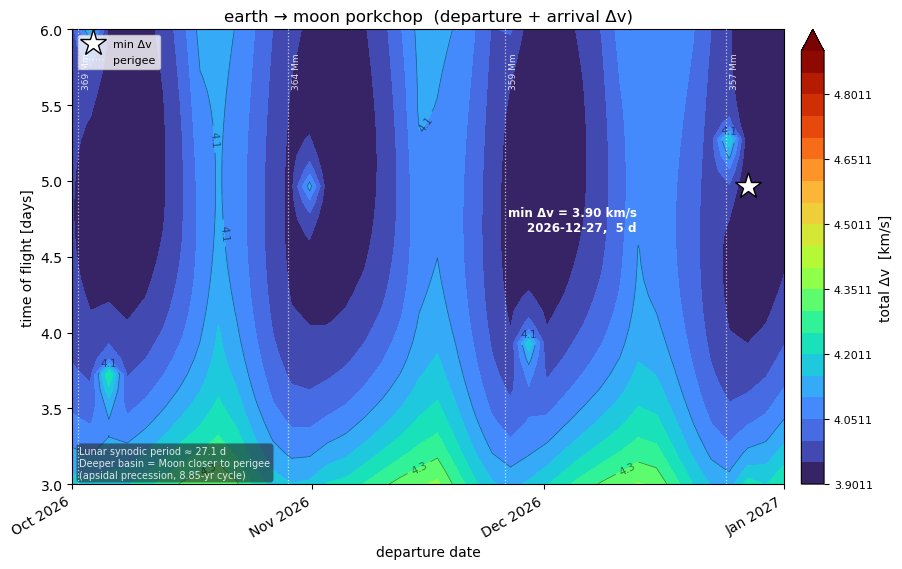

In [5]:
from kalman.apps.space import lunar_porkchop
lunar_grid = lunar_porkchop(start="2026-10-01", end="2027-01-01", n_dep=40, tof_days=(3, 6), n_tof=30)
lbest = lunar_grid["best"]
print("best TLI window:", lbest["dep_date"].iso[:10],
      "| tof %.1f d | \u0394v_TLI %.2f km/s  \u0394v_LOI %.2f km/s"
      % (lbest["tof_days"], lbest["dv_depart_kms"], lbest["dv_arrive_kms"]))
plot_porkchop(lunar_grid)
plt.show()


#### Why do the basins deepen toward December?

Each **basin** in the lunar porkchop is one trans-lunar injection window — the Moon
completing one orbit opens a new low-Δv corridor roughly every **29.5 days** (synodic
period, marked by the white dotted lines at perigee passages).

**Why do successive basins get deeper (lower Δv)?**  The Moon's orbit is slightly
elliptical (eccentricity ≈ 0.055).  Its perigee (closest approach to Earth) precesses
around the Earth on an **8.85-year apsidal cycle**.  In late 2026 the Moon's perigee
happens to be approaching its minimum geocentric distance:

| Perigee | Distance | TLI Δv basin depth |
|---------|----------|--------------------|
| Oct 02  | 369 300 km | shallowest |
| Oct 29  | 364 400 km | ↓ |
| Nov 26  | 359 400 km | ↓ |
| **Dec 24** | **356 700 km** | **deepest** ← global minimum |

A closer Moon means a **shorter transfer-orbit semi-major axis** → less TLI energy
needed.  The basin also widens: more departure dates fall within any fixed Δv budget
because the energy landscape is flatter near a deep minimum.

**Why is the starred minimum at Dec 27 (3 days after perigee) and not exactly at
perigee?**  The porkchop minimises TLI + LOI *combined*.  At perigee the Moon moves
fastest (~1.10 km/s), which raises the arrival relative speed and hence the LOI cost.
Departing 3 days after perigee gives a slightly slower Moon at arrival — the LOI
savings outweigh the small TLI increase, yielding the combined optimum.

**Why does the low-Δv spot shift from about 3.5 days at the beginning of October to about 5 days at the beginning of November?** The answer lies in the changing Earth–Moon geometry. At the beginning of October, the Moon is near perigee, making a fast (~3.5-day) transfer energetically optimal because the target is closer. By the beginning of November, the corresponding launch window occurs with the Moon farther from perigee (toward apogee), so a longer (~5-day) transfer minimizes the total mission Δv. This apparent alternation is produced by the mismatch between the *synodic month* (successive launch windows) and the *anomalistic month* (perigee-to-perigee cycle), which changes the Moon’s distance at each monthly opportunity.

## 2 — Earth → Mars: analytic first estimate (Hohmann)

The **Hohmann transfer** is the fuel-optimal two-impulse path between two *circular, coplanar*
orbits.  It gives three numbers immediately: departure Δv, arrival Δv, and time of flight.
These are the targets every real mission is designed around, even though real orbits are
elliptic and inclined, and a numerical Lambert solve (§ 2b) is always used in practice.

For Earth→Mars the Hohmann gives **~5.6 km/s** total Δv and a **~260-day** flight.
Earth and Mars must be in the right relative geometry; the wait for the next window is
the ~780-day **synodic period**.


In [6]:
h = hohmann_transfer("earth", "mars")
for k, v in h.items():
    print(f"{k:24s}: {v.iso[:16] if hasattr(v,'iso') else round(v,3) if isinstance(v,float) else v}")

departure               : earth
target                  : mars
r1_AU                   : 1.016
r2_AU                   : 1.437
dv_depart_kms           : 2.432
dv_arrive_kms           : 2.23
dv_total_kms            : 4.661
tof_days                : 248.132
phase_angle_deg         : 38.026
synodic_period_days     : 923.969
next_departure          : 2027-01-12 20:27


## 2b — Launch window: the porkchop scan (Lambert)

Real orbits are elliptic and inclined, so Hohmann is only an approximation.  **Lambert's
problem** finds the orbit connecting two arbitrary positions in a specified time of flight —
no coplanarity or circularity required.  Solving Lambert at every (departure date, TOF) node
of a grid produces the *porkchop plot*: contours of total Δv over the launch window.

The minimum-Δv node seeds the cruise: `best_departure` extracts it and builds the initial
state vector `x0 = [r_Earth, v_Lambert]` ready for the EKF integrator.

> **Lambert vs Hohmann:** Lambert is exact for two-body dynamics (Sun only).
> The N-body EKF below adds planetary perturbations on top.


best departure: 2026-10-28 | tof 311 d | Δv_depart 3.05 km/s  C3 9.3 km²/s²


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 86 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 86 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


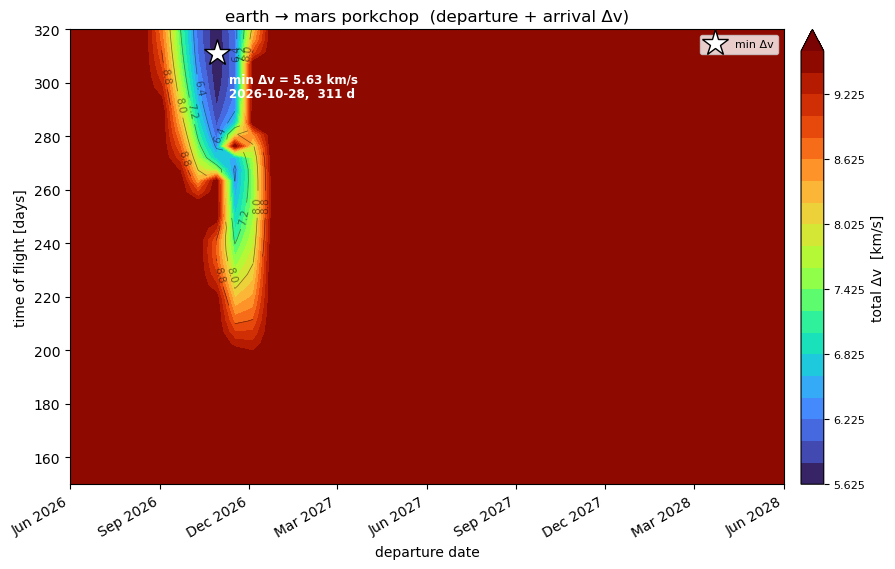

launch from Kennedy Space Center at 05:46 UTC  (Earth-rotation assist 0.364 km/s)


In [7]:
grid = porkchop("earth", "mars", start="2026-06-01", end="2028-06-01",
                n_dep=40, tof_days=(150, 320), n_tof=40)
best = grid["best"]
print("best departure:", best["dep_date"].iso[:10],
      "| tof %.0f d" % best["tof_days"],
      "| \u0394v_depart %.2f km/s  C3 %.1f km\u00b2/s\u00b2" % (best["dv_depart_kms"], best["c3_km2s2"]))

plot_porkchop(grid)
plt.show()

# Earth rotation: best time of day from a launch site (needs network for geocoding/IERS).
try:
    b2 = best_departure("earth", "mars", start="2026-06-01", end="2028-06-01",
                        n_dep=40, tof_days=(150, 320), n_tof=40, site="Kennedy Space Center")
    print("launch from %s at %s UTC  (Earth-rotation assist %.3f km/s)"
          % (b2["site"], b2["launch_time"].iso[11:16], b2["rotation_assist_kms"]))
except Exception as e:
    print("launch-site geocoding skipped (offline):", type(e).__name__)

## 2c — N-body EKF cruise: Earth → Mars

The Lambert initial state is propagated under **Sun + Venus + Jupiter + Saturn** gravity
(N-body dynamics).  Only position is observed — deep-space tracking gives range/range-rate,
modelled here as three Cartesian DSN fixes — and the **EKF reconstructs velocity**.

Because Lambert is a *two-body* solution, the planetary perturbations slowly accumulate
an arrival error that grows over the cruise.  § 2d shows how a mid-course burn (TCM)
nulls that error before arrival.


In [8]:
tof = best["tof_days"]
cruise = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                             dt_s=43200.0, track_Mm=0.02)
cruise.initial_state(best["x0"].reshape(-1, 1), P0=np.diag([1.,1.,1., 1e-4,1e-4,1e-4]))
trip = cruise.sample(tof * DAY, process_noise=False)
est  = cruise.filter(trip.zk)
X, E = np.asarray(trip.xk), np.asarray(est.xk)
err  = np.linalg.norm(X[:, :3] - E[:, :3], axis=1)
print("EKF mean position error: %.1f km  (final %.1f km)" % (err.mean()*1e3, err[-1]*1e3))
print("perturbing bodies:", cruise._field.bodies)
cruise.plot(est, sample=trip, interactive=True, frames=80)     # interactive cruise replay


EKF mean position error: 14.1 km  (final 4.2 km)
perturbing bodies: ('mercury', 'venus', 'jupiter', 'saturn')


## 2d — Mid-course Trajectory Correction Manoeuvre (TCM)

A **TCM** is a small impulsive burn performed mid-cruise to fix the drift between the
planned (two-body Lambert) path and the actual N-body trajectory.  Real missions
(MRO, Cassini, Voyager) apply burns of a few **m/s**; here we start from an
exaggerated 880 m/s injection dispersion so the uncorrected miss is visible at AU scale.

**Procedure at step *k*:**
1. Know current position `r_k` from the EKF.
2. Re-solve Lambert from `r_k` to `r_Mars(t_arrival)` with remaining TOF.
3. Apply Δv = `v_Lambert − v_current` as an impulsive burn.

The EKF is told about the burn via a **control input** `u[k] = Δv`; without it the filter
would see an unexplained jump in position and diverge.

§ 5 adds a second TCM at 80 % TOF using the EKF covariance to decide when the residual
uncertainty is large enough to warrant another burn.


In [9]:
from astropy.time import TimeDelta
mc = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                         dt_s=43200.0, control=True, track_Mm=0.02)
dt = mc._dt; N = int(round(tof * DAY / dt))
arrival  = best["dep_date"] + TimeDelta(N * dt * 1000.0, format="sec")
mars_arr = body_state("mars", arrival)[0]

def fly(x0, kburn=None):
    """Step the N-body model; if kburn is given, re-solve Lambert at that step and apply
    the velocity difference as an impulsive TCM burn (u = v_lambert − v_current)."""
    x = np.asarray(x0, float).reshape(-1).copy(); dv = np.zeros(3)
    hist = [x.copy()]
    for i in range(N):
        u = None
        if i == kburn:                         # re-solve Lambert from current pos → Mars
            v_need, _ = lambert(x[:3], mars_arr, (N - i) * dt, mu=GM_SUN)
            u = dv = v_need - x[3:6]          # Δv = needed vel − current vel
        x = mc.f(x, u=u, t=i * dt).reshape(-1)
        hist.append(x.copy())
    return np.array(hist), dv

# Exaggerated dispersion (~880 m/s) so the uncorrected miss is visible at AU scale.
# A real TCM handles cm/s navigation uncertainty; here we scale up for illustration.
inj   = np.array([0., 0., 0., 0.50, -0.70, 0.20])   # 0.88 km/s off-nominal
x0    = best["x0"] + inj
kburn = N // 2
hist_nom, _  = fly(x0)
hist_cor, dv = fly(x0, kburn=kburn)
miss0 = np.linalg.norm(hist_nom[-1, :3] - mars_arr)
miss1 = np.linalg.norm(hist_cor[-1, :3] - mars_arr)
print("injection dispersion %.0f m/s  ->  arrival miss %.1f AU  (%.0f Mm)"
      % (np.linalg.norm(inj[3:])*1e3, miss0/149597.87, miss0))
print("mid-course TCM burn  %.1f m/s  ->  arrival miss %.0f Mm  (%.0fx closer)"
      % (np.linalg.norm(dv)*1e3, miss1, miss0/max(miss1,1e-9)))
print("TCM Δv vector [km/s]:", np.round(dv, 4))


injection dispersion 883 m/s  ->  arrival miss 0.5 AU  (77449 Mm)
mid-course TCM burn  4872.9 m/s  ->  arrival miss 8 Mm  (10248x closer)
TCM Δv vector [km/s]: [-4.3448  1.8892  1.1397]


### Visualising the correction

Left: static heliocentric overview with labelled events (departure, TCM, arrival).
Right: interactive EKF replay — the orange Δv arrow appears on the TCM frame, the grey
dashed line shows the uncorrected counterfactual, and the gravity readout shows each
planet's share of the total acceleration at each step.


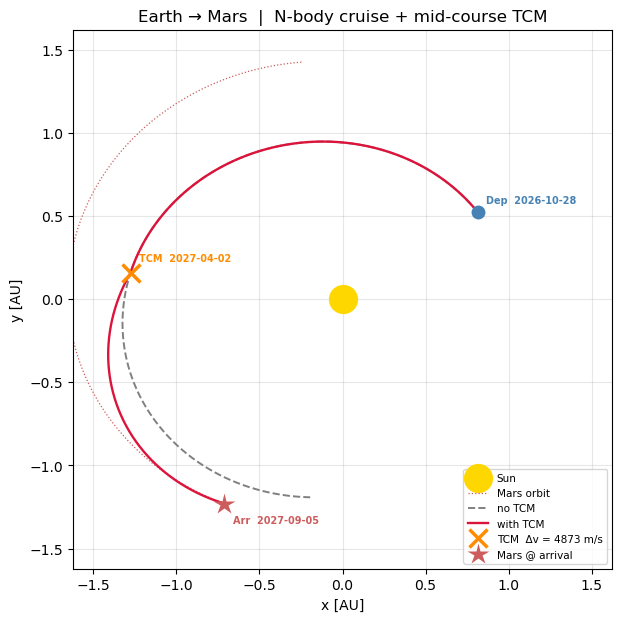

In [10]:
from kalman.framework.io.record import KalmanRecord
from astropy.time import TimeDelta as _TD

uk = np.zeros((N + 1, 3))
uk[kburn] = dv
trip_mc  = KalmanRecord(xk=hist_cor, zk=hist_cor[:, :3])
trip_nom = KalmanRecord(xk=hist_nom, zk=hist_nom[:, :3])
mc.initial_state(x0.reshape(-1, 1), P0=np.diag([1., 1., 1., 1e-4, 1e-4, 1e-4]))
est_mc = mc.filter(trip_mc.zk, u=uk)

# ── Dates for annotation ────────────────────────────────────────────────────
t_dep_str = best['dep_date'].iso[:10]
t_tcm_str = (best['dep_date'] + _TD(float(kburn) * mc._dt * 1e3, format='sec')).iso[:10]
t_arr_str = arrival.iso[:10]

# ── Static heliocentric overview ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0], [0], 'o', color='gold', ms=20, label='Sun')
mars_trk = mc.planet_track('mars', N + 1) / AU
ax.plot(mars_trk[:, 0], mars_trk[:, 1], ':', color='indianred', lw=0.9, label='Mars orbit')
ax.plot(hist_nom[:, 0] / AU, hist_nom[:, 1] / AU, '--', color='0.5', lw=1.4, label='no TCM')
ax.plot(hist_cor[:, 0] / AU, hist_cor[:, 1] / AU, color='crimson', lw=1.7, label='with TCM')
# Departure
dp = hist_cor[0, :2] / AU
ax.plot([dp[0]], [dp[1]], 'o', color='steelblue', ms=10, mec='none', zorder=5)
ax.annotate(f'Dep  {t_dep_str}', dp, xytext=(6, 6), textcoords='offset points',
            fontsize=7, color='steelblue', fontweight='bold')
# TCM burn — cross marker, same style as interactive replay
bp = hist_cor[kburn, :2] / AU
ax.plot([bp[0]], [bp[1]], 'x', color='darkorange', ms=13, mew=2.5, zorder=6,
        label=f'TCM  Δv = {np.linalg.norm(dv)*1e3:.0f} m/s')
ax.annotate(f'TCM  {t_tcm_str}', bp, xytext=(6, 8), textcoords='offset points',
            fontsize=7, color='darkorange', fontweight='bold')
# Mars arrival
mp = np.array([mars_arr[0] / AU, mars_arr[1] / AU])
ax.plot([mp[0]], [mp[1]], '*', color='indianred', ms=16, mec='none', zorder=5, label='Mars @ arrival')
ax.annotate(f'Arr  {t_arr_str}', mp, xytext=(6, -14), textcoords='offset points',
            fontsize=7, color='indianred', fontweight='bold')
lim = 1.15 * np.abs(hist_cor[:, :2] / AU).max()
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_aspect('equal', adjustable='box'); ax.autoscale(False)
ax.set_xlabel('x [AU]'); ax.set_ylabel('y [AU]'); ax.grid(alpha=0.3)
ax.legend(loc='lower right', fontsize=7.5)
ax.set_title('Earth → Mars  |  N-body cruise + mid-course TCM')
plt.show()

# ── Interactive EKF replay (below) ──────────────────────────────────────────
mc.plot(est_mc, sample=trip_mc, interactive=True, frames=80,
        burns=[(kburn, dv)], no_burn=trip_nom)

## 3 — Earth → Jupiter: scaling to the outer solar system

Jupiter is 5.2 AU out (vs Mars at 1.5 AU), so the cruise lasts **2–3 years** and Saturn's
gravitational pull is now a measurable third-body perturbation alongside the inner planets.
Otherwise the pipeline is identical: Hohmann estimate → Lambert porkchop → N-body EKF.

One difference worth noting: the synodic period for Jupiter is **398 days** (just over a year),
so launch windows repeat almost annually, unlike the ~26-month Mars cycle.


Earth -> Jupiter Hohmann:  Δv_total 14.31 km/s   TOF 1019 days   synodic period 409 days
best E->J departure: 2028-12-12 | tof 1010 d | Δv_total 14.73 km/s


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 16 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 16 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133:

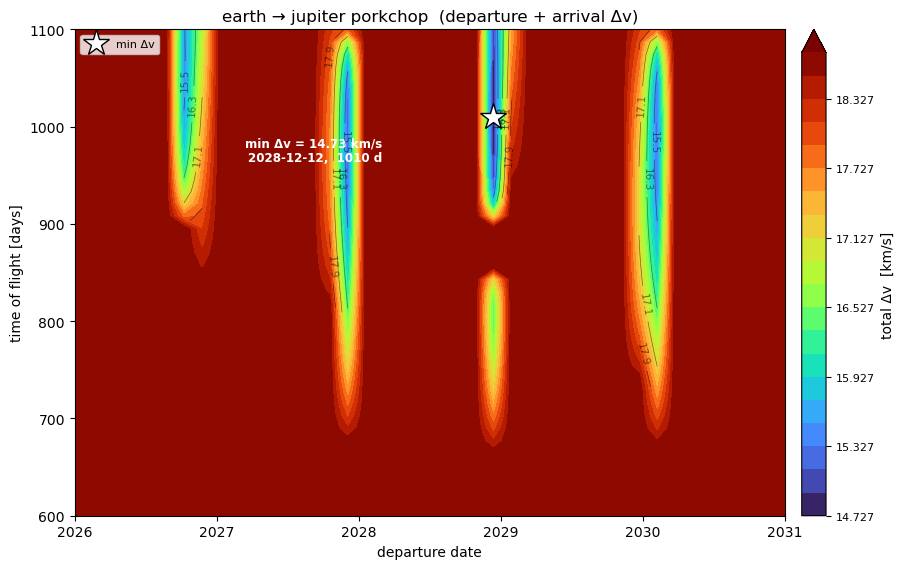

In [11]:
h_jup = hohmann_transfer("earth", "jupiter")
print("Earth -> Jupiter Hohmann:  \u0394v_total %.2f km/s   TOF %.0f days   synodic period %.0f days"
      % (h_jup["dv_total_kms"], h_jup["tof_days"], h_jup["synodic_period_days"]))

grid_jup = porkchop("earth", "jupiter", start="2026-01-01", end="2031-01-01",
                    n_dep=40, tof_days=(600, 1100), n_tof=40)
best_jup = grid_jup["best"]
print("best E->J departure:", best_jup["dep_date"].iso[:10],
      "| tof %.0f d | \u0394v_total %.2f km/s" % (best_jup["tof_days"], best_jup["dv_total_kms"]))
plot_porkchop(grid_jup)
plt.show()


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 527 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 527 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


EKF mean position error: 9171 km  (final 2153 km)
perturbing bodies: ('mercury', 'venus', 'mars', 'saturn')


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 991 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 991 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


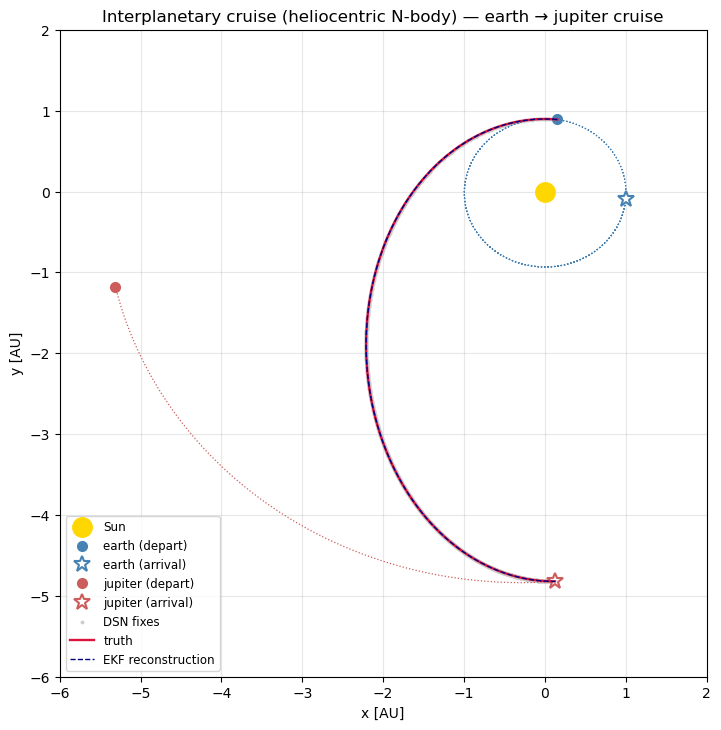

/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


In [12]:
cruise_jup = InterplanetaryModel('earth', 'jupiter', epoch=best_jup['dep_date'],
                                 span_days=best_jup['tof_days'] + 60,
                                 perturbers=('mercury', 'venus', 'mars', 'saturn'),
                                 dt_s=86400.0, track_Mm=0.5)
cruise_jup.initial_state(best_jup['x0'].reshape(-1, 1),
                         P0=np.diag([1., 1., 1., 1e-4, 1e-4, 1e-4]))
trip_jup = cruise_jup.sample(best_jup['tof_days'] * DAY, process_noise=False)
est_jup  = cruise_jup.filter(trip_jup.zk)
err_jup  = np.linalg.norm(
    np.asarray(trip_jup.xk)[:, :3] - np.asarray(est_jup.xk)[:, :3], axis=1)
print('EKF mean position error: %.0f km  (final %.0f km)' % (err_jup.mean()*1e3, err_jup[-1]*1e3))
print('perturbing bodies:', cruise_jup._field.bodies)

# Static overview
cruise_jup.plot(est_jup, sample=trip_jup, xlim=(-6, 2), ylim=(-6, 2))
plt.show()

# Interactive EKF replay (below)
cruise_jup.plot(est_jup, sample=trip_jup, interactive=True, frames=80)


## 4 — Gravity assist: Jupiter as a stepping stone to Saturn

A direct Hohmann from Earth to Saturn costs **15.6 km/s** and takes 6 years.  Chaining
two legs through a **free Jupiter flyby** — letting Jupiter's gravity turn and accelerate
the spacecraft for free — drops the total to **~10 km/s**, the same trick Voyager 1 & 2
and Cassini exploited.

### 4a — Analytic estimate: Hohmann chain

`hohmann_sequence(["earth","jupiter","saturn"])` strings together two analytic Hohmann arcs.
Each leg is treated as circular and coplanar; the flyby is patched-conic (hyperbolic approach
at Jupiter, then a new heliocentric Hohmann departs).  This gives a quick Δv lower bound;
the real optimum needs a Lambert scan (§ 4c).


In [13]:
from kalman.apps.space import gravity_assist, hohmann_sequence, flyby_porkchop, plot_flyby_porkchop

# --- Analytic Hohmann chain: departure burn + free Jupiter flyby + Saturn arrival ---
hs = hohmann_sequence(["earth", "jupiter", "saturn"])
print(f"Direct Earth→Saturn Hohmann :  Δv = {hs['dv_direct_kms']:.2f} km/s")
print(f"Earth→Jupiter→Saturn (free flyby): Δv = {hs['dv_total_kms']:.2f} km/s  "
      f"tof = {hs['tof_days']:.0f} d")
for leg in hs["legs"]:
    print(f"  {leg['departure']:8s} → {leg['target']:8s}: "
          f"Δv_dep={leg['dv_depart_kms']:.2f} km/s  "
          f"Δv_arr={leg['dv_arrive_kms']:.2f} km/s  "
          f"tof={leg['tof_days']:.0f} d")


Direct Earth→Saturn Hohmann :  Δv = 15.58 km/s
Earth→Jupiter→Saturn (free flyby): Δv = 10.20 km/s  tof = 4672 d
  earth    → jupiter : Δv_dep=8.71 km/s  Δv_arr=5.60 km/s  tof=1019 d
  jupiter  → saturn  : Δv_dep=1.73 km/s  Δv_arr=1.49 km/s  tof=3653 d


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


### 4b — The slingshot geometry at Jupiter

In Jupiter's rest frame the spacecraft arrives on a hyperbolic trajectory, curves around
Jupiter, and leaves at the same *speed* — but in the heliocentric frame it has gained
Jupiter's orbital velocity component along its new direction.  The key parameters are:

- **v_∞** — hyperbolic excess speed (spacecraft speed relative to Jupiter at infinity)
- **periapsis altitude** h — closer flyby = larger turn angle δ = 2 arcsin(μ_J / (μ_J + r_p v_∞²))
- **heliocentric Δv** — can reach several km/s for a Jupiter flyby

The calculation below uses `gravity_assist()` with the Lambert-derived arrival v_∞ and
a 500 km periapsis, then computes the patched-conic departure velocity.


In [14]:
# Simplified 1-D geometry: Earth→Jupiter Hohmann speed at Jupiter orbit
R_J = np.linalg.norm(body_state('jupiter')[0])
R_E = np.linalg.norm(body_state('earth')[0])
a_EJ = 0.5 * (R_E + R_J)
v_trans_at_J = float(np.sqrt(GM_SUN * (2 / R_J - 1 / a_EJ)))
v_jup_circ   = float(np.sqrt(GM_SUN / R_J))

ga = gravity_assist(
    v_in_helio     = np.array([v_trans_at_J, 0., 0.]),
    v_planet_helio = np.array([v_jup_circ,   0., 0.]),
    planet         = 'jupiter',
    h_periapsis_km = 500.0,
)
print(f"Approach v_inf           : {ga['v_inf_mag']:.2f} km/s")
print(f"Max turn angle (h=500 km): {ga['turn_angle_deg']:.0f}°")
print(f"Heliocentric speed: {ga['v_helio_in']:.2f} → {ga['v_helio_out']:.2f} km/s  "
      f"(Δv_gain = +{ga['dv_gain_kms']:.2f} km/s)")

plot_gravity_assist(ga, planet='jupiter')


Approach v_inf           : 5.60 km/s
Max turn angle (h=500 km): 159°
Heliocentric speed: 7.37 → 18.30 km/s  (Δv_gain = +10.93 km/s)


### 4c — Two-leg porkchop: Earth → Jupiter → Saturn

`flyby_porkchop` solves two Lambert arcs at every (tof₁, tof₂) grid node and checks the
patched-conic flyby constraint at Jupiter: the required turn angle must be achievable at
the chosen periapsis altitude.  Infeasible nodes are masked.

Unlike the Hohmann chain (§ 4a), this uses **real ephemeris positions**, so it captures
orbital eccentricity, inclination, and the actual Jupiter–Saturn alignment in the chosen
window.  The minimum-Δv node (★) seeds the two-leg interactive trajectory below.


Best E→J→S trajectory (fixed dep 2028-12-12):
  tof₁=1014 d  tof₂=1600 d
  Δv_dep=9.03  Δv_flyby=0.864  Δv_arr=10.36  total=20.26 km/s


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 30 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 30 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 900 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 900 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py

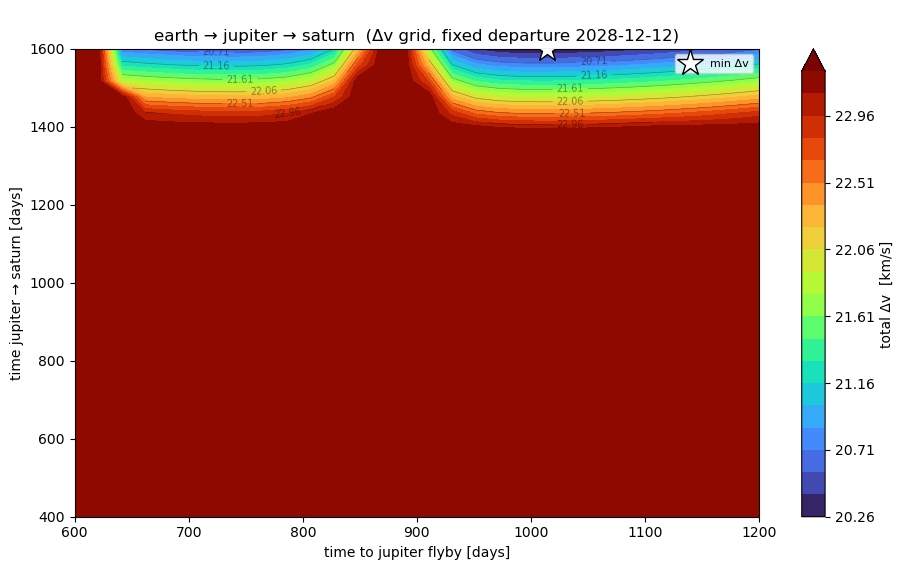

In [15]:
flyby_grid = flyby_porkchop(
    "earth", "jupiter", "saturn", best_jup["dep_date"],
    tof1_range=(600, 1200), tof2_range=(400, 1600),
    n_tof1=30, n_tof2=30, h_min_km=500.0,
)
b2 = flyby_grid["best"]
print(f"Best E→J→S trajectory (fixed dep {b2['dep_date'].iso[:10]}):")
print(f"  tof₁={b2['tof1_days']:.0f} d  tof₂={b2['tof2_days']:.0f} d")
print(f"  Δv_dep={b2['dv_depart_kms']:.2f}  Δv_flyby={b2['dv_flyby_kms']:.3f}  "
      f"Δv_arr={b2['dv_arrive_kms']:.2f}  total={b2['dv_total_kms']:.2f} km/s")
plot_flyby_porkchop(flyby_grid)
plt.show()


### 4d — Two-leg trajectory  *(interactive)*

Both legs are **Lambert arcs** seeded from real ephemeris positions at the best
(tof₁, tof₂) node.  Use the slider to follow the spacecraft through the Jupiter flyby
and on to Saturn.


In [16]:
plot_two_leg(b2)


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


## 5 — Second TCM from EKF covariance

The first TCM (50 % TOF) corrects most of the injection dispersion, but measurement noise
and continuing N-body perturbations accumulate new error over the second half.  When the
EKF position uncertainty σ_r (from the covariance diagonal) exceeds a threshold, a second
correction is worth the propellant.

At 80 % TOF the procedure is the same as § 2d:

$$\Delta v_2 = v_{\mathrm{Lambert}}(r_{\mathrm{EKF}},\,r_{\mathrm{Mars}},\,t_{\mathrm{arr}}) - v_{\mathrm{EKF}}$$

The heliocentric plot shows all three trajectories; the right panel shows EKF σ_r
on a log scale so both burns' effects are visible.


In [17]:
from kalman.framework.io.record import KalmanRecord

kburn2 = int(0.80 * N)

x_ekf2 = np.asarray(est_mc.xk)[kburn2]
P_ekf2 = np.asarray(est_mc.Pk)[kburn2]
nav_sigma_km = float(np.sqrt(np.trace(P_ekf2[:3, :3]))) * 1e3

t_rem2 = (N - kburn2) * mc._dt
r_mars_arr2 = body_state('mars', arrival)[0]
v_lam2, _ = lambert(x_ekf2[:3], r_mars_arr2, t_rem2)
dv2 = v_lam2 - x_ekf2[3:6]

print(f'TCM 1 (mid-course, 50%)  Δv₁ = {np.linalg.norm(dv)*1e3:7.1f} m/s  ← corrects 880 m/s dispersion')
print(f'TCM 2 (pre-arrival, 80%) Δv₂ = {np.linalg.norm(dv2)*1e3:7.1f} m/s  ← corrects residual N-body + nav error')
print(f'Nav σ at TCM 2 burn      : {nav_sigma_km:.1f} km  (1σ from EKF covariance)')
print()
print('The ~24 m/s second burn is typical of real deep-space TCMs:')
print('  MRO  TCM-1 =  18.5 m/s,  TCM-2 = 0.4 m/s')
print('  MSL  TCM-1 =   5.0 m/s,  TCM-4 = 0.9 m/s')

# EKF re-run with both burns so the filter knows about dv2
uk2 = np.zeros((N + 1, 3))
uk2[kburn]  = dv
uk2[kburn2] = dv2
est_mc2 = mc.filter(trip_mc.zk, u=uk2)


TCM 1 (mid-course, 50%)  Δv₁ =  4872.9 m/s  ← corrects 880 m/s dispersion
TCM 2 (pre-arrival, 80%) Δv₂ =    23.4 m/s  ← corrects residual N-body + nav error
Nav σ at TCM 2 burn      : 3.1 km  (1σ from EKF covariance)

The ~24 m/s second burn is typical of real deep-space TCMs:
  MRO  TCM-1 =  18.5 m/s,  TCM-2 = 0.4 m/s
  MSL  TCM-1 =   5.0 m/s,  TCM-4 = 0.9 m/s


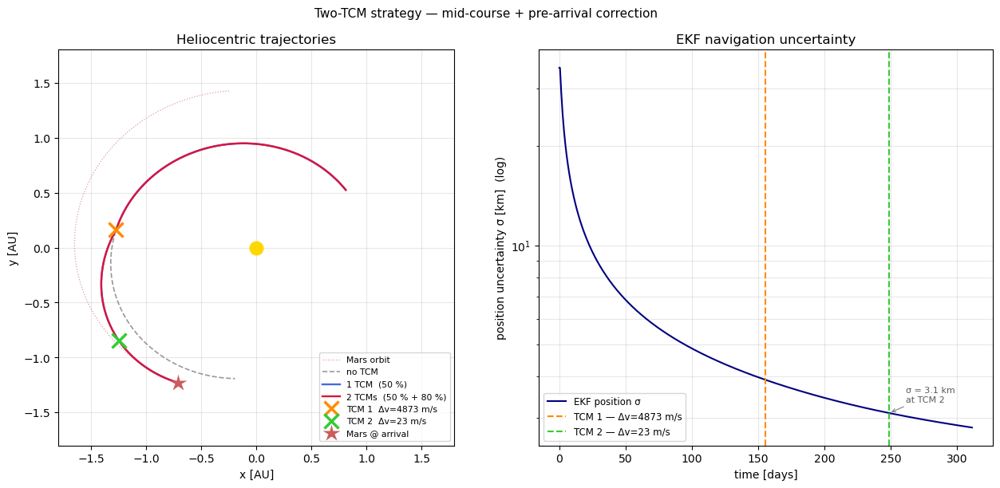

In [18]:
from kalman.runtime.astro import rk4 as _rk4

def _helio_deriv(state, t):
    r = state[:3]; rn = np.linalg.norm(r)
    return np.concatenate([state[3:6], -GM_SUN * r / rn**3])

# Re-integrate leg 2 with dv2 applied for the static overview
s2 = hist_cor[kburn2].copy(); s2[3:6] += dv2
leg2_traj = [s2[:3].copy()]
for i in range(len(hist_cor) - kburn2 - 1):
    s2 = _rk4(s2, i * mc._dt, mc._dt, _helio_deriv)
    leg2_traj.append(s2[:3].copy())
leg2_traj = np.array(leg2_traj)
traj_2 = np.vstack([hist_cor[:kburn2, :3], leg2_traj])

# ── Static overview ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
ax = axes[0]
mars_trk2 = mc.planet_track('mars', len(hist_cor))
ax.plot(mars_trk2[:,0]/AU, mars_trk2[:,1]/AU, ':', color='indianred', lw=0.9, alpha=0.6, label='Mars orbit')
ax.plot(hist_nom[:,0]/AU, hist_nom[:,1]/AU, '--', color='0.6', lw=1.2, label='no TCM')
ax.plot(hist_cor[:,0]/AU, hist_cor[:,1]/AU, color='royalblue', lw=1.7, label='1 TCM  (50 %)')
ax.plot(traj_2[:,0]/AU, traj_2[:,1]/AU, color='crimson', lw=1.7, label='2 TCMs  (50 % + 80 %)')
# TCM markers — cross, matching interactive style
ax.plot(*hist_cor[kburn,:2]/AU, 'x', color='darkorange', ms=13, mew=2.5, zorder=6,
        label=f'TCM 1  Δv={np.linalg.norm(dv)*1e3:.0f} m/s')
ax.plot(*hist_cor[kburn2,:2]/AU, 'x', color='limegreen', ms=13, mew=2.5, zorder=6,
        label=f'TCM 2  Δv={np.linalg.norm(dv2)*1e3:.0f} m/s')
ax.plot(r_mars_arr2[0]/AU, r_mars_arr2[1]/AU, '*', color='indianred', ms=16, mec='none', zorder=5, label='Mars @ arrival')
ax.plot(0, 0, 'o', color='gold', ms=12, zorder=6)
ax.autoscale(False); ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('x [AU]'); ax.set_ylabel('y [AU]')
ax.set_title('Heliocentric trajectories'); ax.legend(fontsize=7.8, loc='lower right'); ax.grid(alpha=0.3)
ax2 = axes[1]
Pk_all  = np.asarray(est_mc.Pk)
sigma_r = np.sqrt(np.trace(Pk_all[:,:3,:3], axis1=1, axis2=2)) * 1e3
t_days_all = np.arange(len(sigma_r)) * mc._dt / DAY
ax2.semilogy(t_days_all, sigma_r, color='navy', lw=1.5, label='EKF position σ')
ax2.axvline(kburn  * mc._dt / DAY, color='darkorange', ls='--', lw=1.5, label=f'TCM 1 — Δv={np.linalg.norm(dv)*1e3:.0f} m/s')
ax2.axvline(kburn2 * mc._dt / DAY, color='limegreen',  ls='--', lw=1.5, label=f'TCM 2 — Δv={np.linalg.norm(dv2)*1e3:.0f} m/s')
ax2.annotate(f'σ = {nav_sigma_km:.1f} km\nat TCM 2',
             xy=(kburn2 * mc._dt / DAY, nav_sigma_km), xytext=(15, 10), textcoords='offset points',
             fontsize=8, color='0.35', arrowprops=dict(arrowstyle='->', color='0.5', lw=0.8))
ax2.set_xlabel('time [days]'); ax2.set_ylabel('position uncertainty σ [km]  (log)')
ax2.set_title('EKF navigation uncertainty'); ax2.legend(fontsize=8.5); ax2.grid(alpha=0.3, which='both')
plt.suptitle('Two-TCM strategy — mid-course + pre-arrival correction', fontsize=11)
plt.tight_layout(); plt.show()

# ── Interactive EKF replay with both burns + no-TCM counterfactual ───────
mc.plot(est_mc2, sample=trip_mc, interactive=True, frames=80,
        burns=[(kburn, dv), (kburn2, dv2)], no_burn=trip_nom)

## 6 — Cassini VVEJGA: replicating the Grand Tour

**Cassini–Huygens** (launched 15 October 1997) took **6 years 9 months** to reach Saturn,
using one of the most intricate gravity-assist sequences ever flown:

> Earth → Venus → Venus → Earth → Jupiter → Saturn

The route — **V**enus–**V**enus–**E**arth–**J**upiter **G**ravity **A**ssist (VVEJGA) —
made three trips around the inner solar system before departing for the outer system,
accumulating ~15 km/s of free Δv from planetary flybys:

| Leg | Departure | Arrival | TOF |
|-----|-----------|---------|-----|
| 1  | Earth     | Venus   | 1997-10-15 → 1998-04-26 | 193 d |
| 2  | Venus     | Venus   | 1998-04-26 → 1999-06-24 | 424 d |
| 3  | Venus     | Earth   | 1999-06-24 → 1999-08-18 |  55 d |
| 4  | Earth     | Jupiter | 1999-08-18 → 2000-12-30 | 500 d |
| 5  | Jupiter   | Saturn  | 2000-12-30 → 2004-07-01 | 1279 d |

`chain_lambert` solves five Lambert arcs (one per leg) using the actual historical flyby
dates, then `plot_multi_leg` animates the full trajectory from launch to Saturn orbit
insertion.  The patched-conic solver gives approximate Δv at each flyby node; the true
burns were ≲ 1 m/s correction manoeuvres — the planets did the real work.

In [19]:
from astropy.time import Time
from kalman.apps.space import chain_lambert, plot_multi_leg

cassini_sequence = ["earth", "venus", "venus", "earth", "jupiter", "saturn"]
cassini_dates    = [
    Time("1997-10-15"),   # launch
    Time("1998-04-26"),   # Venus 1 flyby
    Time("1999-06-24"),   # Venus 2 flyby
    Time("1999-08-18"),   # Earth flyby
    Time("2000-12-30"),   # Jupiter flyby
    Time("2004-07-01"),   # Saturn orbit insertion
]

legs = chain_lambert(cassini_sequence, cassini_dates)

print("Cassini VVEJGA — Lambert solution per leg")
print(f"{'Leg':>3}  {'Route':>18}  {'TOF (d)':>8}  {'Δv_flyby (m/s)':>15}")
for i, lg in enumerate(legs):
    route = f"{lg['departure']}→{lg['arrival']}"
    print(f"{i+1:>3}  {route:>18}  {lg['tof_days']:>8.0f}  {lg['dv_flyby_kms']*1e3:>15.0f}")

total_tof = sum(lg["tof_days"] for lg in legs)
print(f"\nTotal mission time: {total_tof:.0f} days  ({total_tof/365.25:.1f} years)")

# Two-panel: LEFT = inner solar system (VVEJ flybys), RIGHT = full Earth→Saturn scale.
# zoom_lim="auto" sizes the left panel to the tightest box that fits all inner arcs
# (< 4 AU) without clipping; legs that exit the zoom box are suppressed there to avoid
# discontinuous line artefacts (e.g. the Earth→Jupiter leg clipping at x = 2.1 AU).
plot_multi_leg(legs,
               title="Cassini VVEJGA  (1997–2004)  —  Earth → Venus → Venus → Earth → Jupiter → Saturn",
               extra_planets=("mars",),
               frames=120,
               zoom_lim="auto")

Cassini VVEJGA — Lambert solution per leg
Leg               Route   TOF (d)   Δv_flyby (m/s)
  1         earth→venus       193                0
  2         venus→venus       424             4412
  3         venus→earth        55             3814
  4       earth→jupiter       500             5912
  5      jupiter→saturn      1279             1969

Total mission time: 2451 days  (6.7 years)


## Further reading

- **More complex gravity assists.**  Cassini used Venus–Venus–Earth–Jupiter (VVEJGA) to reach
  Saturn.  Try chaining `flyby_porkchop` calls or extending `hohmann_sequence` to four legs.
- **Autonomous optical navigation.**  Real probes update the EKF with star-tracker bearing
  measurements (angle-only).  Swap the DSN position model for an `H = angle` observation
  matrix and observe how the covariance grows differently.
- Back to the pad: **06 — Rocket Science** covers liftoff, guided ascent and the gimballed
  landing.
